In [ ]:
%%capture
!pip install diffusers
import matplotlib.pyplot as plt
from PIL import Image # used to represent images

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

CLIPTextModel LOAD REPORT from: /root/.cache/huggingface/hub/models--CompVis--stable-diffusion-v1-4/snapshots/133a221b8aa7292a167afc5127cb63fb5005638b/text_encoder
Key                                | Status     |  | 
-----------------------------------+------------+--+-
text_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

StableDiffusionSafetyChecker LOAD REPORT from: /root/.cache/huggingface/hub/models--CompVis--stable-diffusion-v1-4/snapshots/133a221b8aa7292a167afc5127cb63fb5005638b/safety_checker
Key                                               | Status     |  | 
--------------------------------------------------+------------+--+-
vision_model.vision_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  0%|          | 0/50 [00:00<?, ?it/s]

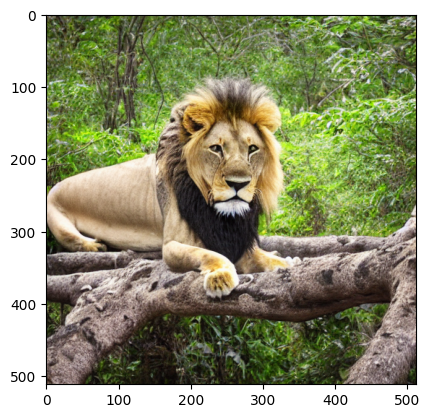

In [ ]:
z#a tool used to generate images using stable diffusion
from diffusers import DiffusionPipeline
generator = DiffusionPipeline.from_pretrained("CompVis/stable-diffusion-v1-4")
#specifies what GPUs should be used for this generation
generator.to("cuda")

image = generator("Photo of a lion in a jungle ").images[0]
plt.imshow(image);

In [ ]:
# pipeline used for image to image generation with stable diffusion
from diffusers import StableDiffusionImg2ImgPipeline
# loads a pretrained generator model
generator = StableDiffusionImg2ImgPipeline.from_pretrained("runwayml/stable-diffusion-v1-5")
# moves the generator model to the GPU (CUDA) for faster processing
generator.to("cuda")
init_image = Image.open("Hill and River.png")
init_image.thumbnail((1416, 664)) # resizes the image to prepare it as input of the model
plt.imshow(init_image);

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

CLIPTextModel LOAD REPORT from: /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-v1-5/snapshots/451f4fe16113bff5a5d2269ed5ad43b0592e9a14/text_encoder
Key                                | Status     |  | 
-----------------------------------+------------+--+-
text_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

StableDiffusionSafetyChecker LOAD REPORT from: /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-v1-5/snapshots/451f4fe16113bff5a5d2269ed5ad43b0592e9a14/safety_checker
Key                                               | Status     |  | 
--------------------------------------------------+------------+--+-
vision_model.vision_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


FileNotFoundError: [Errno 2] No such file or directory: 'Hill and River.png'

In [ ]:
# a detailed prompt describing the desired visual
# for the produced image
prompt = "A realistic mountainlandscape with a large castle."
image = generator(prompt=prompt,image = init_image, strength=1).images[0]
plt.imshow(image);

NameError: name 'init_image' is not defined

  0%|          | 0/50 [00:00<?, ?it/s]

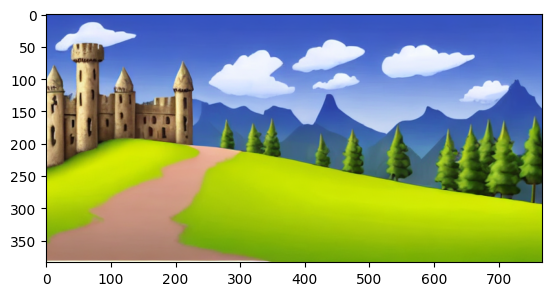

In [ ]:
# generate a new image based on the prompt and the
# initial image using the generator model
image = generator(prompt=prompt,
image = init_image, strength=1).images[0]
plt.imshow(image);

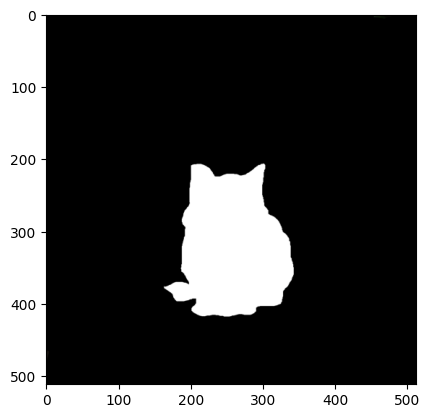

In [ ]:
# tool used for text-guided image in-painting
from diffusers import StableDiffusionInpaintPipeline
init_image = Image.open("cat_on_bench.jpg").resize((512, 512))
plt.imshow(init_image);
mask_image = Image.open("cat_mask.jpg").resize((512, 512))
plt.imshow(mask_image);

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

An error occurred while trying to fetch /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/vae: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/vae.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
An error occurred while trying to fetch /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/unet: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/unet.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


  0%|          | 0/50 [00:00<?, ?it/s]

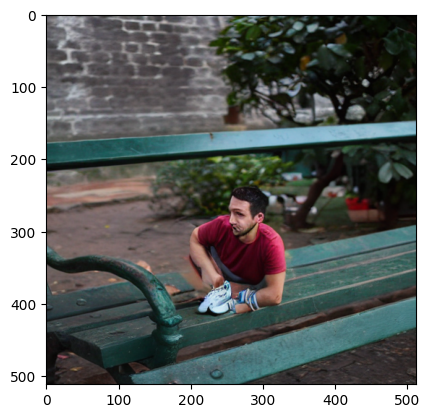

In [ ]:
generator = StableDiffusionInpaintPipeline.from_pretrained("runwayml/stable-diffusion-inpainting")
generator = generator.to("cuda")
prompt = "A photo of an guy"
image = generator(prompt=prompt, image=init_image, mask_image=mask_image).images[0]
plt.imshow(image);

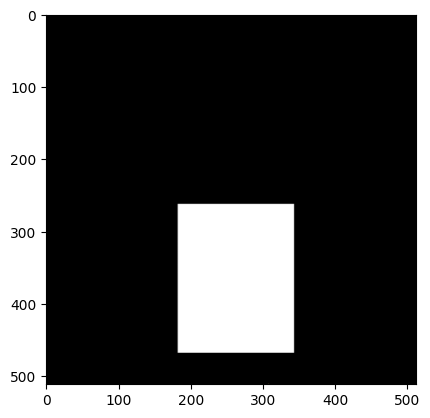

In [ ]:
init_image = Image.open("desk.jpg").resize((512, 512))
plt.imshow(init_image);
mask_image = Image.open("desk_mask.jpg").resize((512, 512))
plt.imshow(mask_image);

  0%|          | 0/50 [00:00<?, ?it/s]

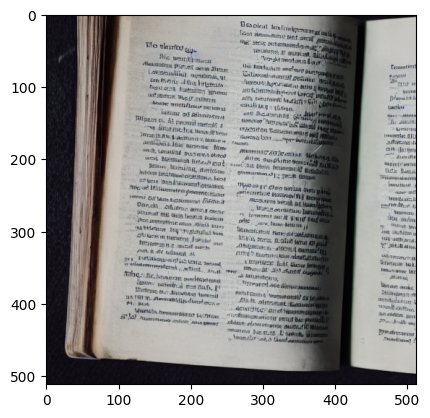

In [ ]:
prompt = "A photo of a book"
image = generator(prompt=prompt, image=init_image, mask_image=mask_image).images[0]
plt.imshow(image);